# Laboratorio 4: Construcción de Portafolios — Markowitz, Black-Litterman y Risk Parity 

**Curso:** Finanzas Computacionales  
**Programa:** Magíster en Business Analytics (UAI)  
**Autor:** Francisco Andrés Cisternas García  
**Fecha:** 6 de noviembre de 2026


In [1]:
# --- Setup ---
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # quantstats pide Arial; si no está, usa otra

# Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
import scipy.optimize as sco
import quantstats as qs
import riskfolio as rp

# Paleta de colores y figuras
NAVY, BLUE, ACCENT, GREY = "#1F3864", "#2E5496", "#C55A11", "#8A8F98"
GREEN, RED, GOLDC = "#2E7D57", "#B23A3A", "#B8860B"
COLS = [NAVY, BLUE, ACCENT, GREEN, GOLDC, GREY]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlecolor": NAVY, "font.size": 11})

# Parámetros financieros fundamentales
RF = 0.02          # tasa libre de riesgo anual
ANN = 252          # días hábiles por año
rfd = RF / ANN     # tasa libre de riesgo diaria (Riskfolio trabaja con datos diarios)
print("Entorno listo. Riskfolio-Lib", rp.__version__, "| quantstats", qs.__version__)

Entorno listo. Riskfolio-Lib 7.4.1 | quantstats 0.0.86


## Datos, respaldo CSV, benchmark y momentos anuales.

In [18]:
# 4 activos de renta variable (2 defensivos, 2 crecimiento), 1 activo de bonos y 1 de commodities
TICKERS = {"KO": "KO", "JNJ": "JNJ", "GOOGL": "GOOGL", "NVDA": "NVDA", "BND": "BND", "USO": "USO"}
# Benchmark: 60% Renta Variable (15% en cada acción), 30% Renta Fija (BND), 10% Materias Primas (USO)
BENCHMARK = {"KO": 0.15, "JNJ": 0.15, "GOOGL": 0.15, "NVDA": 0.15, "BND": 0.30, "USO": 0.10}
# Datos
INICIO = "2018-01-01"
RESPALDO = "mis_precios_taller4.csv"

def get_prices(tickers, backup=RESPALDO, start=INICIO, end=None):
    import contextlib, io, logging
    try:
        import yfinance as yf
        logging.getLogger("yfinance").setLevel(logging.CRITICAL)
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            data = yf.download(list(tickers.keys()), start=start, end=end, auto_adjust=True, progress=False)
        px = data["Close"].dropna()
        if px.shape[0] < 500:
            raise RuntimeError("datos insuficientes")
        
        # Guardar en CSV de respaldo
        px_final = px.rename(columns=tickers)[list(tickers.values())]
        px_final.to_csv(backup)
        print(f"Precios reales descargados de yfinance y respaldados en: {backup}")
        return px_final
    except Exception as e:
        print(f"No se pudo descargar ({e}). Usando respaldo local: {backup}")
        return pd.read_csv(backup, index_col=0, parse_dates=True)

# Retornos y momentos historicos
precios = get_prices(TICKERS, backup=RESPALDO, start=INICIO)
retornos = precios.pct_change().dropna()
ASSETS = list(retornos.columns)
n = len(ASSETS)
R = retornos.values
print(f"{len(retornos)} días, desde {retornos.index[0]:%Y-%m-%d} hasta {retornos.index[-1]:%Y-%m-%d}")
print("\n----- Retornos -----")
display(retornos.head())

avg_returns = retornos.mean() * ANN        # retorno esperado anual (promedio histórico)
cov_mat = retornos.cov() * ANN             # covarianza anual
vol = np.sqrt(np.diag(cov_mat))
mu, cov = avg_returns.values, cov_mat.values
resumen = pd.DataFrame({"Retorno esp.": mu, "Volatilidad": vol, "Sharpe indiv.": (mu - RF) / vol}, index=ASSETS)
print("\n----- Retornos, Volatilidad y Sharpe indvidual -----")
resumen.style.format({"Retorno esp.": "{:.1%}", "Volatilidad": "{:.1%}", "Sharpe indiv.": "{:.2f}"})

Precios reales descargados de yfinance y respaldados en: mis_precios_taller4.csv
2225 días, desde 2018-01-03 hasta 2026-11-09

----- Retornos -----


Ticker,KO,JNJ,GOOGL,NVDA,BND,USO
Date,,,,,,
2018-01-03,-0.002196,0.009552,0.017061,0.065814,0.000861,0.022370
2018-01-04,0.014085,-0.000071,0.003884,0.005271,-0.000492,0.002431
2018-01-05,-0.000217,0.008253,0.013260,0.008475,-0.001352,-0.004850
2018-01-08,-0.001519,0.001270,0.003531,0.030641,0.000123,0.005686
2018-01-09,0.005000,0.015857,-0.001274,-0.000271,-0.002954,0.015347



----- Retornos, Volatilidad y Sharpe indvidual -----


,Retorno esp.,Volatilidad,Sharpe indiv.
KO,13.4%,19.3%,0.59
JNJ,12.7%,19.8%,0.54
GOOGL,24.1%,31.3%,0.70
NVDA,53.3%,50.2%,1.02
BND,1.7%,5.8%,-0.05
USO,13.0%,41.0%,0.27


## Correlaciones y pruebas de Jarque-Bera/asimetría/curtosis.

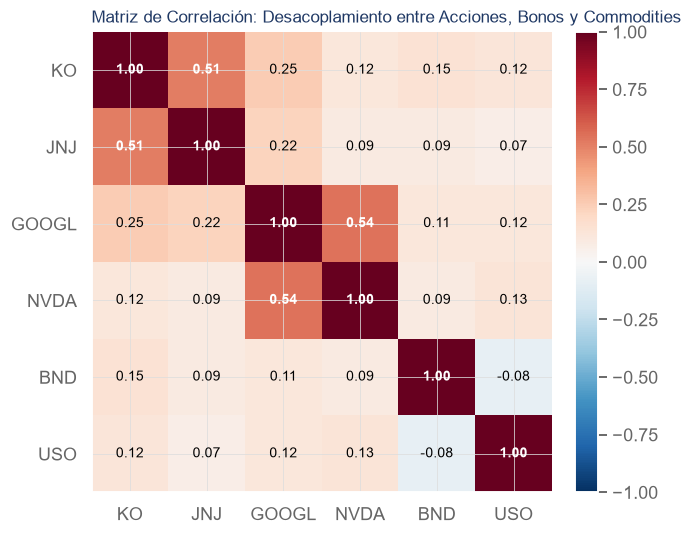

In [27]:
# Matriz de correlación
corr = retornos.corr()

fig, ax = plt.subplots(figsize=(6.2, 5.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(ASSETS)
ax.set_yticks(range(n)); ax.set_yticklabels(ASSETS)
for i in range(n):
    for j in range(n):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(val) > 0.45 else "black", weight="bold" if abs(val) > 0.5 else "normal")
ax.set_title("Matriz de Correlación: Desacoplamiento entre Acciones, Bonos y Commodities", loc="left", fontsize=11)
fig.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig("fig1_correlaciones.png", dpi=150)
plt.show()

### Diagnostico de correlaciones:
Tenemos 3 bloques de activos, los defensivos compuestos por KO y JNO; Los de crecimiento por NVDA Y GOOGL; Y, por ultimo, los desacoplados por los ETF BND y USO. Los defensivos son acciones de consumo masivo y salud; Los de crecimiento son tecnologias que van enc recimiento; Los ultimos son dos ETF que funcionan como un escudo de amortiguación ante cambios bruscos en los mercados financieros.

- Los activos defnesivos presentan una correlación positiva moderada (0,51).
- Los de crecimiento presentan una correlación moderada (0,54).
- Los desacoplados presentan correlacionas bajas o nulas con respecto a las acciones(entre -0,08 a 0,15).

,Asimetría (Diaria),Curtosis Exceso (Diaria),JB Estadístico,JB p-valor,Curtosis Exceso (Mensual)
KO,-0.504,8.14,"6,232.2",0.0000e+00,0.88
JNJ,-0.232,7.93,"5,854.4",0.0000e+00,-0.22
GOOGL,-0.064,4.35,"1,757.4",0.0000e+00,1.08
NVDA,0.137,4.83,"2,172.9",0.0000e+00,-0.13
BND,-0.892,32.71,"99,500.8",0.0000e+00,0.34
USO,-0.957,12.77,"15,468.1",0.0000e+00,5.99
Portafolio 1/N,-0.705,9.43,"8,426.4",0.0000e+00,1.43


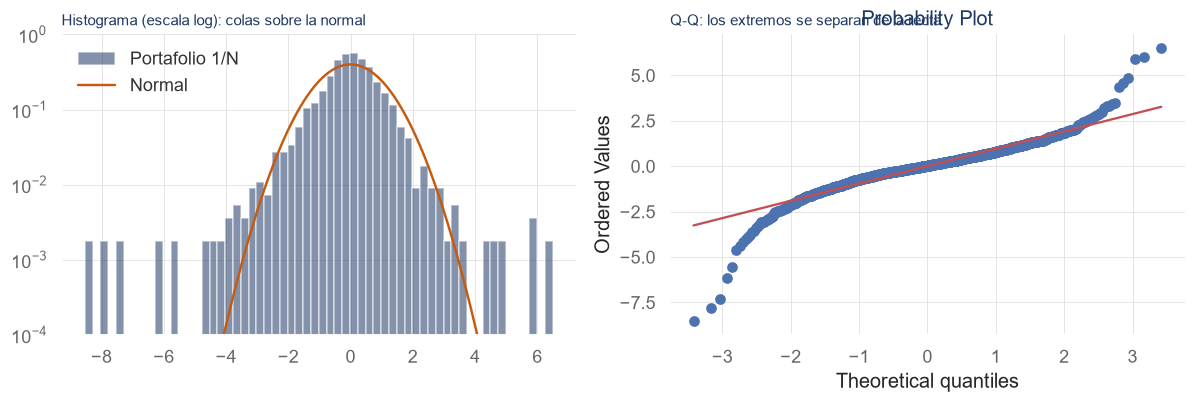

In [ ]:
# Normalidad

# Portafolio equiponderado
w_eq = np.ones(n) / n
r_eq = pd.Series(R @ w_eq, index=retornos.index, name="Portafolio 1/N")
rets_m = (1 + retornos).resample("ME").prod() - 1
r_eq_m = (1 + r_eq).resample("ME").prod() - 1

# Medición de las estadisticas de normalidad
def normalidad(serie_d, serie_m):
    jb_stat, jb_pval = stats.jarque_bera(serie_d)
    return {
        "Asimetría (Diaria)": stats.skew(serie_d),
        "Curtosis Exceso (Diaria)": stats.kurtosis(serie_d),
        "JB Estadístico": jb_stat,
        "JB p-valor": jb_pval,
        "Curtosis Exceso (Mensual)": stats.kurtosis(serie_m)
    }

tab_norm = pd.DataFrame({a: normalidad(retornos[a], rets_m[a]) for a in ASSETS} |
                        {"Portafolio 1/N": normalidad(r_eq, r_eq_m)}).T

display(tab_norm.style.format({
    "Asimetría (Diaria)": "{:.3f}",
    "Curtosis Exceso (Diaria)": "{:.2f}",
    "JB Estadístico": "{:,.1f}",
    "JB p-valor": "{:.4e}",
    "Curtosis Exceso (Mensual)": "{:.2f}"
}))

# Estandarización
z = (r_eq - r_eq.mean()) / r_eq.std()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
# Colas pesadas (Histograma en escala logaritmica)
axes[0].hist(z, bins=60, density=True, color=NAVY, alpha=0.55, label="Portafolio 1/N")
xs = np.linspace(-5.5, 5.5, 300)
axes[0].plot(xs, stats.norm.pdf(xs), color=ACCENT, lw=1.6, label="Normal")
axes[0].set_yscale("log"); axes[0].set_ylim(1e-4, 1); axes[0].legend(frameon=False)
axes[0].set_title("Histograma (escala log): colas sobre la normal", loc="left", fontsize=10)

# Grafico Q-Q Normal
stats.probplot(z, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q: los extremos se separan de la recta", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## Frontera de Markowitz desde(0,0), LMC, Mínima Varianza y Máximo Sharpe.

In [29]:
# Black-Litterman con 𝛿, 𝑤𝑚𝑘t y 2 visiones explícitas.

In [30]:
# Risk Parity con verificación analítica de contribuciones.

In [31]:
# División temporal (In-Sample / Out-of-Sample) y tabla comparativa contra el Benchmark.

In [32]:
# Bootstrap de pesos y análisis de rotación.

In [33]:
# Exportación de imágenes y redacción del reporte Markdown de 1.500 palabras.